# TP : Comptage des mots Comparaison de quatre méthodes

## 1. Introduction

L'objectif de ce TP est de comparer quatre approches permettant de compter
le nombre d'occurrences de chaque mot dans un fichier texte.

Les quatre méthodes étudiées sont :

1. Python simple : comptage séquentiel à l'aide d'un dictionnaire.
2. Pseudo-MapReduce Python : simulation des étapes Map, Shuffle et Reduce.
3. Hadoop MapReduce : utilisation du framework Hadoop pour effectuer
   le comptage des mots.
4. PySpark : traitement en mémoire avec Apache Spark, en mode local.

Nous allons mesurer les temps d'exécution de ces quatre méthodes sur
des fichiers de différentes tailles, vérifier que les résultats obtenus
sont identiques et analyser leurs performances.

## 2. Environnement et outils utilisés

- Système d'exploitation : Ubuntu Linux.
- Langage : Python 3.10.12.
- Environnement Python : environnement virtuel `.venv`.
- Outil de développement : Jupyter Notebook.
- Framework distribué : Apache Hadoop 3.4.0 en mode pseudo-distribué.
- Moteur en mémoire : Apache Spark 4.2.0 via PySpark, en mode local.

## 3. Génération du fichier de test

Nous créons un fichier texte nommé `mots.txt` contenant un mot par ligne.

Le fichier contient volontairement des répétitions afin de pouvoir
mesurer le nombre d'occurrences de chaque mot.

Ce fichier servira de référence pour tester les trois méthodes.

In [1]:
from pathlib import Path
from collections import Counter

# Définition du fichier de test
fichier_mots = Path("mots.txt")

# Liste de mots avec des répétitions
mots = [
    "chat", "chien", "chat", "voiture", "chat",
    "arbre", "chien", "fleur", "chat", "voiture",
    "soleil", "arbre", "chat", "chien", "fleur",
    "livre", "chat", "montagne", "chien", "soleil"
]

# Création du fichier : un mot par ligne
with open(fichier_mots, "w", encoding="utf-8") as f:
    for mot in mots:
        f.write(mot + "\n")

print("Fichier créé :", fichier_mots.resolve())
print("Nombre de lignes :", len(mots))
print("Contenu du fichier :")
print(fichier_mots.read_text(encoding="utf-8"))

Fichier créé : /home/ssl/Documents/5A/S9/BD/TP_Comptage_Mots/mots.txt
Nombre de lignes : 20
Contenu du fichier :
chat
chien
chat
voiture
chat
arbre
chien
fleur
chat
voiture
soleil
arbre
chat
chien
fleur
livre
chat
montagne
chien
soleil



## 4. Méthode 1 : Python simple

### Principe

La première méthode utilise un dictionnaire Python pour compter
les occurrences de chaque mot dans le fichier.

Le programme lit le fichier, récupère tous les mots avec la méthode
`split()`, puis parcourt les mots un par un.

Pour chaque mot, le compteur correspondant est incrémenté de 1.
Les résultats sont ensuite triés par ordre décroissant du nombre
d'occurrences.

Cette méthode est séquentielle : les mots sont traités les uns
après les autres, sans parallélisation.

In [2]:
def compter_occurrences(fichier):
    """
    Compte les occurrences de chaque mot dans un fichier texte.

    Paramètre :
        fichier : chemin du fichier à analyser.

    Retour :
        Un dictionnaire contenant chaque mot et son nombre d'occurrences.
    """
    with open(fichier, "r", encoding="utf-8") as f:
        mots = f.read().split()

    compteur = {}

    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1

    return compteur


# Exécution de la méthode 1
resultats_python = compter_occurrences(fichier_mots)

# Affichage des résultats par ordre décroissant
for mot, nombre in sorted(
    resultats_python.items(),
    key=lambda element: element[1],
    reverse=True
):
    print(f"{mot} : {nombre}")

chat : 6
chien : 4
voiture : 2
arbre : 2
fleur : 2
soleil : 2
livre : 1
montagne : 1


In [3]:
# Vérification du nombre total de mots comptabilisés
total_mots = sum(resultats_python.values())

print("Nombre total de mots :", total_mots)
print("Nombre de mots différents :", len(resultats_python))

assert total_mots == 20, "Erreur : le total doit être égal à 20."

print("Vérification réussie : les 20 mots ont été comptabilisés.")

Nombre total de mots : 20
Nombre de mots différents : 8
Vérification réussie : les 20 mots ont été comptabilisés.


### Mesure du temps d'exécution

Nous utilisons le module `time` pour mesurer le temps nécessaire
à l'exécution de la méthode Python simple.

La mesure inclut la lecture du fichier et le comptage des mots.

In [4]:
import time

debut = time.perf_counter()

resultats_python = compter_occurrences(fichier_mots)

fin = time.perf_counter()

temps_python = fin - debut

print(f"Temps d'exécution : {temps_python:.6f} seconde(s)")

Temps d'exécution : 0.000177 seconde(s)


## 5. Méthode 2 : Pseudo-MapReduce Python

### Principe

Cette deuxième méthode reproduit localement les trois étapes du modèle
MapReduce : Map, Shuffle et Reduce.

- Map : chaque mot est transformé en une paire (mot, 1).
- Shuffle : les valeurs associées à chaque mot sont regroupées.
- Reduce : les valeurs de chaque groupe sont additionnées pour obtenir
  le nombre total d'occurrences.

Contrairement à Hadoop, cette implémentation s'exécute entièrement
sur une seule machine. Elle permet néanmoins de comprendre
l'organisation du traitement MapReduce.

In [5]:
from collections import defaultdict


def mapper(ligne):
    """
    Transforme chaque mot d'une ligne en une paire (mot, 1).
    """
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]


def shuffle(mapped_data):
    """
    Regroupe les valeurs associées à chaque mot.
    """
    grouped = defaultdict(list)

    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)

    return grouped


def reducer(grouped_data):
    """
    Additionne les valeurs associées à chaque mot.
    """
    reduced = {}

    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)

    return reduced


# Exécution de la méthode 2
mapped = []

with open(fichier_mots, "r", encoding="utf-8") as f:
    for ligne in f:
        mapped.extend(mapper(ligne))

grouped = shuffle(mapped)
resultats_mapreduce = reducer(grouped)

# Affichage des résultats
for mot, nombre in sorted(
    resultats_mapreduce.items(),
    key=lambda element: element[1],
    reverse=True
):
    print(f"{mot} : {nombre}")

chat : 6
chien : 4
voiture : 2
arbre : 2
fleur : 2
soleil : 2
livre : 1
montagne : 1


In [6]:
# Comparaison des résultats des deux méthodes
assert resultats_python == resultats_mapreduce, (
    "Erreur : les deux méthodes donnent des résultats différents."
)

print("Vérification réussie : les deux méthodes donnent les mêmes résultats.")

print("Total des mots :", sum(resultats_mapreduce.values()))
print("Nombre de mots différents :", len(resultats_mapreduce))

Vérification réussie : les deux méthodes donnent les mêmes résultats.
Total des mots : 20
Nombre de mots différents : 8


In [7]:
debut = time.perf_counter()

mapped = []

with open(fichier_mots, "r", encoding="utf-8") as f:
    for ligne in f:
        mapped.extend(mapper(ligne))

grouped = shuffle(mapped)
resultats_mapreduce = reducer(grouped)

fin = time.perf_counter()

temps_mapreduce = fin - debut

print(f"Temps d'exécution : {temps_mapreduce:.6f} seconde(s)")

Temps d'exécution : 0.000350 seconde(s)


## 6. Méthode 3 : Hadoop MapReduce

### Principe

Les deux premières méthodes s'exécutent dans un unique processus Python.
Cette troisième méthode confie le même calcul à Apache Hadoop, qui applique
le modèle MapReduce à travers une véritable infrastructure distribuée.

Le traitement se déroule en plusieurs étapes :

1. Le fichier est copié depuis le disque local vers HDFS, le système de
   fichiers distribué de Hadoop, où il est découpé en blocs.
2. YARN alloue des conteneurs et lance une tâche Map par bloc d'entrée.
3. Chaque Map émet des paires `(mot, 1)`, qu'un combiner agrège localement.
4. La phase Shuffle redistribue les paires par clé entre les nœuds.
5. Les tâches Reduce additionnent les valeurs et écrivent le résultat
   dans HDFS.

Nous utilisons l'exemple `wordcount` fourni avec Hadoop, qui implémente
exactement cet algorithme.

### Dispositif

Le cluster fonctionne en mode pseudo-distribué : tous les démons (NameNode,
DataNode, ResourceManager, NodeManager) tournent sur la même machine. Il n'y
a donc aucun gain de parallélisme réel à en attendre, mais le chemin
d'exécution est celui d'un vrai cluster, avec son coût d'orchestration.

In [8]:
import os
import subprocess
import getpass
from pathlib import Path

# ============================================================
# CONFIGURATION DE L'ENVIRONNEMENT HADOOP
# ============================================================

HADOOP_HOME = Path.home() / "hadoop-3.4.0"

env = os.environ.copy()
env["JAVA_HOME"] = "/usr/lib/jvm/java-11-openjdk-amd64"
env["HADOOP_HOME"] = str(HADOOP_HOME)
env["HADOOP_CONF_DIR"] = str(HADOOP_HOME / "etc/hadoop")
env["PATH"] = (
    f"{env['JAVA_HOME']}/bin:"
    f"{HADOOP_HOME}/bin:"
    f"{HADOOP_HOME}/sbin:"
    + env.get("PATH", "")
)

# Chemins des exécutables et du jar d'exemples
HADOOP = str(HADOOP_HOME / "bin/hadoop")
HDFS = str(HADOOP_HOME / "bin/hdfs")
JAR = str(HADOOP_HOME / "share/hadoop/mapreduce/hadoop-mapreduce-examples-3.4.0.jar")

# Répertoires de travail dans HDFS, propres à l'utilisateur courant
RACINE_HDFS = f"/user/{getpass.getuser()}"
ENTREE_HDFS = f"{RACINE_HDFS}/input"
SORTIE_HDFS = f"{RACINE_HDFS}/output"


def executer_hadoop(arguments):
    """
    Exécute une commande Hadoop et retourne sa sortie standard.

    Lève une RuntimeError si la commande échoue.
    """
    resultat = subprocess.run(
        arguments,
        env=env,
        capture_output=True,
        text=True
    )

    if resultat.returncode != 0:
        raise RuntimeError(resultat.stderr)

    return resultat.stdout


# Vérification de l'installation
print(executer_hadoop([HADOOP, "version"]).splitlines()[0])

# Vérification de l'état du cluster : le NodeManager doit être sain,
# sinon les jobs restent indéfiniment en état ACCEPTED.
etat_noeuds = executer_hadoop([
    str(HADOOP_HOME / "bin/yarn"), "node", "-list", "-all"
])

print(etat_noeuds.strip().splitlines()[-1])

Hadoop 3.4.0


ssl-VivoBook-ASUSLaptop-X515EA-F515EA:45251	       SHUTDOWN	ssl-VivoBook-ASUSLaptop-X515EA-F515EA:8042	                           0


In [9]:
import time

# ============================================================
# EXÉCUTION DU JOB WORDCOUNT SUR LE FICHIER DE RÉFÉRENCE
# ============================================================

fichier_source = Path("mots.txt")

assert fichier_source.exists(), f"Fichier introuvable : {fichier_source}"

# Préparation : répertoire d'entrée propre, pas d'ancienne sortie
executer_hadoop([HDFS, "dfs", "-rm", "-r", "-f", ENTREE_HDFS, SORTIE_HDFS])
executer_hadoop([HDFS, "dfs", "-mkdir", "-p", ENTREE_HDFS])

# Chargement du fichier dans HDFS
debut = time.perf_counter()

executer_hadoop([
    HDFS, "dfs", "-put", "-f",
    str(fichier_source),
    f"{ENTREE_HDFS}/{fichier_source.name}"
])

temps_chargement = time.perf_counter() - debut

print(f"Chargement dans HDFS : {temps_chargement:.3f} seconde(s)")

# Exécution du job MapReduce
debut = time.perf_counter()

executer_hadoop([HADOOP, "jar", JAR, "wordcount", ENTREE_HDFS, SORTIE_HDFS])

temps_hadoop = time.perf_counter() - debut

print(f"Job MapReduce : {temps_hadoop:.3f} seconde(s)")
print(f"Total : {temps_chargement + temps_hadoop:.3f} seconde(s)")

Chargement dans HDFS : 1.496 seconde(s)


Job MapReduce : 15.460 seconde(s)
Total : 16.956 seconde(s)


In [10]:
import pandas as pd

# ============================================================
# LECTURE DU RÉSULTAT ET VÉRIFICATION
# ============================================================

def lire_resultat_hadoop(dossier_sortie):
    """
    Lit les fichiers part-* produits par Hadoop et reconstruit
    le dictionnaire des occurrences.
    """
    sortie = executer_hadoop([
        HDFS, "dfs", "-cat", f"{dossier_sortie}/part-*"
    ])

    occurrences = {}

    for ligne in sortie.strip().splitlines():
        mot, nombre = ligne.rsplit("\t", 1)
        occurrences[mot] = int(nombre)

    return occurrences


resultats_hadoop = lire_resultat_hadoop(SORTIE_HDFS)

# Affichage par ordre décroissant
for mot, nombre in sorted(
    resultats_hadoop.items(),
    key=lambda element: element[1],
    reverse=True
):
    print(f"{mot} : {nombre}")

# Les trois méthodes doivent donner exactement le même résultat
assert resultats_hadoop == resultats_python, (
    "Erreur : Hadoop et Python simple donnent des résultats différents."
)

assert resultats_hadoop == resultats_mapreduce, (
    "Erreur : Hadoop et le pseudo-MapReduce donnent des résultats différents."
)

print("\nVérification réussie : les trois méthodes donnent le même résultat.")
print("Total des mots :", sum(resultats_hadoop.values()))
print("Nombre de mots différents :", len(resultats_hadoop))

chat : 6
chien : 4
arbre : 2
fleur : 2
soleil : 2
voiture : 2
livre : 1
montagne : 1

Vérification réussie : les trois méthodes donnent le même résultat.
Total des mots : 20
Nombre de mots différents : 8


### Première comparaison

Sur ce fichier de 20 mots, Hadoop est plusieurs milliers de fois plus lent
que les deux implémentations Python. Ce résultat n'est pas surprenant : le
temps mesuré est presque entièrement constitué du démarrage des machines
virtuelles Java, de la négociation des ressources avec YARN et des écritures
dans HDFS. Le calcul lui-même est négligeable.

Ce coût fixe est indépendant de la taille des données. La section suivante
vérifie comment il se comporte lorsque le volume augmente.

## 7. Méthode 4 : PySpark

### Principe

Apache Spark reprend le modèle MapReduce mais corrige sa principale faiblesse :
Hadoop écrit les résultats intermédiaires sur disque entre chaque étape, alors
que Spark conserve les données en mémoire tout au long du traitement.

Le calcul s'exprime ici sous forme de transformations enchaînées sur un RDD
(*Resilient Distributed Dataset*) :

1. `textFile` lit le fichier et le découpe en partitions.
2. `flatMap` transforme chaque ligne en une suite de mots.
3. `map` associe la valeur 1 à chaque mot, ce qui correspond à la phase Map.
4. `reduceByKey` additionne les valeurs par mot. Spark applique au passage une
   agrégation locale sur chaque partition avant l'échange réseau, ce qui joue
   le rôle du combiner de Hadoop.

Ces transformations sont *paresseuses* : rien n'est calculé avant l'appel à
`collect()`, qui déclenche l'exécution et rapatrie le résultat.

### Dispositif

Spark est lancé en mode local avec deux threads de travail (`local[2]`), ce qui
donne un parallélisme réel sur deux cœurs, sans cluster ni démon à administrer.

La session Spark est créée une seule fois et réutilisée pour toutes les mesures.
Son démarrage, qui coûte plusieurs secondes, est donc exclu des temps relevés —
contrairement à Hadoop, où chaque job paie l'intégralité du coût de lancement.

In [11]:
# Installation de PySpark dans l'environnement du notebook
%pip install --quiet "pyspark>=4.0,<5"

Note: you may need to restart the kernel to use updated packages.


In [12]:
import os
import sys
from operator import add
from pathlib import Path

from pyspark.sql import SparkSession

# ============================================================
# CONFIGURATION DE LA SESSION SPARK
# ============================================================

# Spark 4 exige Java 17 au minimum, alors que Hadoop tourne ici sous Java 11.
# Les deux cohabitent : Hadoop reçoit son JAVA_HOME via le dictionnaire `env`
# construit à la section 6, Spark lit celui du processus Python.
for repertoire_java in [
    Path("/usr/lib/jvm/java-17-openjdk-amd64"),
    Path("/usr/lib/jvm/java-21-openjdk-amd64"),
]:
    if (repertoire_java / "bin/java").is_file():
        os.environ["JAVA_HOME"] = str(repertoire_java)
        break

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

# Répertoire de travail pour les fichiers temporaires de Spark
dossier_temporaire_spark = Path("spark_tmp").resolve()
dossier_temporaire_spark.mkdir(parents=True, exist_ok=True)

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("ComptageMots")
    .config("spark.ui.enabled", "false")
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.local.dir", str(dossier_temporaire_spark))
    .config("spark.pyspark.python", sys.executable)
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Version de Spark :", spark.version)
print("Mode d'exécution :", spark.sparkContext.master)
print("Parallélisme par défaut :", spark.sparkContext.defaultParallelism)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/13 18:14:05 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/13 18:14:05 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


Version de Spark : 4.2.0
Mode d'exécution : local[2]
Parallélisme par défaut : 2


In [13]:
import time

# ============================================================
# COMPTAGE DES MOTS AVEC SPARK
# ============================================================

def compter_spark(fichier):
    """
    Compte les occurrences de chaque mot avec Spark.

    Le chemin est converti en URI absolue : sans cela, Spark interprète
    les chemins relatifs par rapport au répertoire des exécuteurs.
    """
    comptages = (
        spark.sparkContext
        .textFile(Path(fichier).resolve().as_uri())
        .flatMap(lambda ligne: ligne.split())
        .map(lambda mot: (mot, 1))
        .reduceByKey(add)
    )

    return dict(comptages.collect())


# Première exécution, volontairement ignorée : elle supporte le coût
# d'initialisation des exécuteurs Python.
compter_spark(fichier_mots)

debut = time.perf_counter()

resultats_spark = compter_spark(fichier_mots)

temps_spark = time.perf_counter() - debut

# Affichage par ordre décroissant
for mot, nombre in sorted(
    resultats_spark.items(),
    key=lambda element: element[1],
    reverse=True
):
    print(f"{mot} : {nombre}")

print(f"\nTemps d'exécution : {temps_spark:.6f} seconde(s)")

chat : 6
chien : 4
voiture : 2
arbre : 2
fleur : 2
soleil : 2
livre : 1
montagne : 1

Temps d'exécution : 0.282479 seconde(s)


In [14]:
import pandas as pd

# ============================================================
# VÉRIFICATION ET COMPARAISON DES QUATRE MÉTHODES
# ============================================================

assert resultats_spark == resultats_python, (
    "Erreur : Spark et Python simple donnent des résultats différents."
)

assert resultats_spark == resultats_mapreduce, (
    "Erreur : Spark et le pseudo-MapReduce donnent des résultats différents."
)

assert resultats_spark == resultats_hadoop, (
    "Erreur : Spark et Hadoop donnent des résultats différents."
)

print("Vérification réussie : les quatre méthodes donnent le même résultat.\n")

comparaison = pd.DataFrame({
    "Méthode": [
        "Python simple",
        "Pseudo-MapReduce",
        "Hadoop MapReduce",
        "PySpark local[2]",
    ],
    "Temps d'exécution (s)": [
        temps_python,
        temps_mapreduce,
        temps_hadoop,
        temps_spark,
    ],
})

comparaison["Rapport au plus rapide"] = (
    comparaison["Temps d'exécution (s)"] / comparaison["Temps d'exécution (s)"].min()
).round(1)

display(comparaison)

Vérification réussie : les quatre méthodes donnent le même résultat.



,Méthode,Temps d'exécution (s),Rapport au plus rapide
0,Python simple,0.000177,1.0
1,Pseudo-MapReduce,0.000350,2.0
2,Hadoop MapReduce,15.459789,87112.6
3,PySpark local[2],0.282479,1591.7


### Lecture des résultats

Sur ce fichier de 20 mots, Spark se place entre les implémentations Python et
Hadoop. Il évite le lancement d'un job YARN et les allers-retours sur HDFS,
mais conserve un coût fixe : planification du graphe d'exécution, répartition
des partitions entre les threads et sérialisation des données vers les
processus Python.

Ce surcoût n'a de sens que s'il est amorti par le volume de données. La section
suivante mesure à partir de quelle taille cela devient le cas.

## 8. Comparaison des performances sur différentes tailles de fichiers

### Objectif

Nous comparons les quatre méthodes en faisant varier la taille des fichiers
d'entrée, de 100 lignes à 1 Go.

Les fichiers sont générés en dupliquant le contenu de `mots.txt`. Chaque ligne
contient un mot.

Le protocole de mesure diffère selon le coût de chaque méthode :

- pour les deux implémentations Python, trois exécutions et médiane retenue ;
- pour Hadoop et Spark, une seule exécution par fichier, chaque mesure coûtant
  plusieurs secondes à plusieurs minutes.

Pour Hadoop, le chargement du fichier dans HDFS est chronométré séparément du
job MapReduce : les autres méthodes lisent directement le fichier local, et
mélanger les deux fausserait la comparaison.

In [15]:
from pathlib import Path

# ============================================================
# 1. CONFIGURATION
# ============================================================

fichier_source = Path("mots.txt")
dossier_tests = Path("fichiers_test")
dossier_tests.mkdir(parents=True, exist_ok=True)

# Lire le fichier source
contenu = fichier_source.read_bytes()

if not contenu:
    raise ValueError("Le fichier mots.txt est vide.")

# Compter les lignes du fichier source
with fichier_source.open("rb") as f:
    lignes_source = f.readlines()

if not lignes_source:
    raise ValueError("Le fichier source ne contient aucune ligne.")

print(f"Fichier source : {fichier_source}")
print(f"Nombre de lignes initial : {len(lignes_source)}")


# ============================================================
# 2. DÉFINIR LES FICHIERS À GÉNÉRER
# ============================================================

tailles_fichiers = {
    "100_lignes": ("lignes", 100),
    "1000_lignes": ("lignes", 1_000),
    "10000_lignes": ("lignes", 10_000),
    "100000_lignes": ("lignes", 100_000),
    "1_Mo": ("taille", 1_000_000),
    "10_Mo": ("taille", 10_000_000),
    "100_Mo": ("taille", 100_000_000),
    "500_Mo": ("taille", 500_000_000),
    "1_Go": ("taille", 1_000_000_000),
}


# ============================================================
# 3. GÉNÉRATION D'UN FICHIER AVEC UN NOMBRE DE LIGNES FIXE
# ============================================================

def generer_fichier_lignes(nombre_lignes, destination):
    with destination.open("wb") as sortie:
        lignes_ecrites = 0

        while lignes_ecrites < nombre_lignes:
            for ligne in lignes_source:
                if lignes_ecrites >= nombre_lignes:
                    break

                sortie.write(ligne)
                lignes_ecrites += 1


# ============================================================
# 4. GÉNÉRATION D'UN FICHIER AVEC UNE TAILLE FIXE
# ============================================================

def generer_fichier_taille(taille_cible, destination):
    taille_bloc = len(contenu)

    repetitions = taille_cible // taille_bloc
    reste = taille_cible % taille_bloc

    with destination.open("wb") as sortie:
        # Écriture par blocs pour limiter les opérations d'écriture
        bloc_repetitions = contenu * 1000

        while repetitions >= 1000:
            sortie.write(bloc_repetitions)
            repetitions -= 1000

        if repetitions > 0:
            sortie.write(contenu * repetitions)

        if reste > 0:
            sortie.write(contenu[:reste])


# ============================================================
# 5. GÉNÉRATION DE TOUS LES FICHIERS
# ============================================================

fichiers_generes = {}

for nom, (type_generation, valeur) in tailles_fichiers.items():

    fichier_test = dossier_tests / f"mots_{nom}.txt"

    if type_generation == "lignes":
        generer_fichier_lignes(valeur, fichier_test)
    else:
        generer_fichier_taille(valeur, fichier_test)

    fichiers_generes[nom] = fichier_test

    taille_octets = fichier_test.stat().st_size

    with fichier_test.open("rb") as f:
        nombre_lignes_reel = sum(1 for _ in f)

    print(
    f"{nom:15} | "
    f"Lignes : {nombre_lignes_reel:>10,} | "
    f"Taille : {taille_octets / 1024:>12,.2f} Ko"
)

print("\nTous les fichiers ont été générés.")

Fichier source : mots.txt
Nombre de lignes initial : 20
100_lignes      | Lignes :        100 | Taille :         0.60 Ko
1000_lignes     | Lignes :      1,000 | Taille :         6.01 Ko
10000_lignes    | Lignes :     10,000 | Taille :        60.06 Ko
100000_lignes   | Lignes :    100,000 | Taille :       600.59 Ko
1_Mo            | Lignes :    162,602 | Taille :       976.56 Ko
10_Mo           | Lignes :  1,626,017 | Taille :     9,765.62 Ko


100_Mo          | Lignes : 16,260,163 | Taille :    97,656.25 Ko


500_Mo          | Lignes : 81,300,814 | Taille :   488,281.25 Ko


1_Go            | Lignes : 162,601,627 | Taille :   976,562.50 Ko

Tous les fichiers ont été générés.


In [16]:
import time
import statistics
import pandas as pd
from collections import defaultdict


# ============================================================
# MÉTHODE 1 : PYTHON SIMPLE
# ============================================================

def compter_python(fichier):
    with open(fichier, "r", encoding="utf-8") as f:
        mots = f.read().split()

    compteur = {}

    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1

    return compteur


# Version progressive : lecture ligne par ligne
def compter_python_progressif(fichier):
    compteur = {}

    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            for mot in ligne.split():
                compteur[mot] = compteur.get(mot, 0) + 1

    return compteur


# ============================================================
# MÉTHODE 2 : PSEUDO-MAPREDUCE
# ============================================================

def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]


def shuffle(mapped_data):
    grouped = defaultdict(list)

    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)

    return grouped


def reducer(grouped_data):
    return {
        mot: sum(valeurs)
        for mot, valeurs in grouped_data.items()
    }


def compter_pseudo_mapreduce(fichier):
    mapped = []

    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))

    grouped = shuffle(mapped)

    return reducer(grouped)


# Variante économe en mémoire
def compter_mapreduce_econome(fichier):
    compteur = defaultdict(int)

    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            for mot, valeur in mapper(ligne):
                compteur[mot] += valeur

    return dict(compteur)


# ============================================================
# MÉTHODE 3 : HADOOP
# ============================================================

def mesurer_hadoop(fichier):
    """
    Charge le fichier dans HDFS, exécute le job wordcount et lit le résultat.

    Retour :
        (temps de chargement, temps du job, dictionnaire des occurrences)
    """
    executer_hadoop([HDFS, "dfs", "-rm", "-r", "-f", ENTREE_HDFS, SORTIE_HDFS])
    executer_hadoop([HDFS, "dfs", "-mkdir", "-p", ENTREE_HDFS])

    debut = time.perf_counter()

    executer_hadoop([
        HDFS, "dfs", "-put", "-f",
        str(fichier),
        f"{ENTREE_HDFS}/{fichier.name}"
    ])

    duree_chargement = time.perf_counter() - debut

    debut = time.perf_counter()

    executer_hadoop([HADOOP, "jar", JAR, "wordcount", ENTREE_HDFS, SORTIE_HDFS])

    duree_job = time.perf_counter() - debut

    resultat = lire_resultat_hadoop(SORTIE_HDFS)

    # Libérer l'espace occupé dans HDFS
    executer_hadoop([HDFS, "dfs", "-rm", "-r", "-f", ENTREE_HDFS, SORTIE_HDFS])

    return duree_chargement, duree_job, resultat


# ============================================================
# MESURE DU TEMPS D'EXÉCUTION
# ============================================================

def mesurer_temps(fonction, fichier, repetitions=3):
    """
    Exécute la fonction plusieurs fois et retourne (médiane des durées, résultat).
    """
    durees = []

    for _ in range(repetitions):
        debut = time.perf_counter()
        resultat = fonction(fichier)
        fin = time.perf_counter()

        durees.append(fin - debut)

    return statistics.median(durees), resultat


# ============================================================
# COMPARAISON DES MÉTHODES
# ============================================================

resultats_benchmarks = []

for nom, fichier in fichiers_generes.items():

    taille_octets = fichier.stat().st_size
    taille_mo = taille_octets / 1024 ** 2

    print(f"\nTest du fichier : {nom}  ({taille_mo:,.2f} Mo)")

    # Choisir les implémentations Python selon la taille du fichier :
    # au-delà de 10 Mo, les versions qui matérialisent toutes les paires
    # intermédiaires dépassent la mémoire disponible.
    if taille_octets <= 10_000_000:

        fonction_simple = compter_python
        fonction_mapreduce = compter_pseudo_mapreduce

        nom_simple = "Python simple"
        nom_mapreduce = "Pseudo-MapReduce"

    else:

        fonction_simple = compter_python_progressif
        fonction_mapreduce = compter_mapreduce_econome

        nom_simple = "Python progressif"
        nom_mapreduce = "MapReduce économe"

    # --- Méthodes Python : médiane de trois exécutions ---
    temps_simple, resultat_simple = mesurer_temps(fonction_simple, fichier)
    temps_mapreduce, resultat_mapreduce = mesurer_temps(fonction_mapreduce, fichier)

    assert resultat_simple == resultat_mapreduce, (
        f"Résultats différents entre les deux méthodes Python pour {nom}"
    )

    # --- Méthode 3 : Hadoop ---
    chargement_hdfs, temps_job_hadoop, resultat_hadoop = mesurer_hadoop(fichier)

    assert resultat_hadoop == resultat_simple, (
        f"Hadoop donne un résultat différent pour {nom}"
    )

    # --- Méthode 4 : Spark, une seule exécution ---
    temps_job_spark, resultat_spark = mesurer_temps(
        compter_spark, fichier, repetitions=1
    )

    assert resultat_spark == resultat_simple, (
        f"Spark donne un résultat différent pour {nom}"
    )

    print(
        f"  Python : {temps_simple:8.3f} s | "
        f"MapReduce : {temps_mapreduce:8.3f} s | "
        f"Hadoop : {temps_job_hadoop:8.3f} s "
        f"(+ {chargement_hdfs:.3f} s de chargement) | "
        f"Spark : {temps_job_spark:8.3f} s | OK"
    )

    # Nombre de lignes réellement présentes dans le fichier
    with fichier.open("rb") as f:
        nombre_lignes = sum(1 for _ in f)

    resultats_benchmarks.append({
        "Fichier": nom,
        "Nombre de lignes": nombre_lignes,
        "Taille (Mo)": round(taille_mo, 2),
        "Méthode Python": nom_simple,
        "Python (s)": round(temps_simple, 6),
        "Méthode MapReduce": nom_mapreduce,
        "MapReduce (s)": round(temps_mapreduce, 6),
        "Hadoop job (s)": round(temps_job_hadoop, 3),
        "Hadoop chargement (s)": round(chargement_hdfs, 3),
        "Spark (s)": round(temps_job_spark, 3),
    })


# ============================================================
# AFFICHAGE DU TABLEAU FINAL
# ============================================================

df_benchmarks = pd.DataFrame(resultats_benchmarks)

print("\nTous les tests sont réussis.")

display(df_benchmarks)


Test du fichier : 100_lignes  (0.00 Mo)


  Python :    0.000 s | MapReduce :    0.000 s | Hadoop :   15.585 s (+ 1.676 s de chargement) | Spark :    0.241 s | OK

Test du fichier : 1000_lignes  (0.01 Mo)


  Python :    0.000 s | MapReduce :    0.000 s | Hadoop :   15.638 s (+ 1.584 s de chargement) | Spark :    0.219 s | OK

Test du fichier : 10000_lignes  (0.06 Mo)


  Python :    0.001 s | MapReduce :    0.005 s | Hadoop :   15.603 s (+ 1.436 s de chargement) | Spark :    0.225 s | OK

Test du fichier : 100000_lignes  (0.59 Mo)


  Python :    0.014 s | MapReduce :    0.048 s | Hadoop :   15.707 s (+ 1.765 s de chargement) | Spark :    0.297 s | OK

Test du fichier : 1_Mo  (0.95 Mo)


...

  Python :   17.305 s | MapReduce :   37.723 s | Hadoop :   41.941 s (+ 2.417 s de chargement) | Spark :   62.057 s | OK



Test du fichier : 1_Go  (953.67 Mo)


  Python :   34.976 s | MapReduce :   76.375 s | Hadoop :   76.482 s (+ 2.994 s de chargement) | Spark :  121.248 s | OK



Tous les tests sont réussis.


,Fichier,Nombre de lignes,Taille (Mo),Méthode Python,Python (s),Méthode MapReduce,MapReduce (s),Hadoop job (s),Hadoop chargement (s),Spark (s)
0,100_lignes,100,0.00,Python simple,0.000030,Pseudo-MapReduce,0.000074,15.585,1.676,0.241
1,1000_lignes,1000,0.01,Python simple,0.000196,Pseudo-MapReduce,0.000492,15.638,1.584,0.219
2,10000_lignes,10000,0.06,Python simple,0.001357,Pseudo-MapReduce,0.005001,15.603,1.436,0.225
3,100000_lignes,100000,0.59,Python simple,0.014379,Pseudo-MapReduce,0.048171,15.707,1.765,0.297
4,1_Mo,162602,0.95,Python simple,0.036024,Pseudo-MapReduce,0.078582,15.651,1.684,0.289
5,10_Mo,1626017,9.54,Python simple,0.206917,Pseudo-MapReduce,0.778032,16.674,1.780,1.155
6,100_Mo,16260163,95.37,Python progressif,3.447001,MapReduce économe,7.581764,24.583,1.815,14.597
7,500_Mo,81300814,476.84,Python progressif,17.304986,MapReduce économe,37.723068,41.941,2.417,62.057
8,1_Go,162601627,953.67,Python progressif,34.976089,MapReduce économe,76.374986,76.482,2.994,121.248


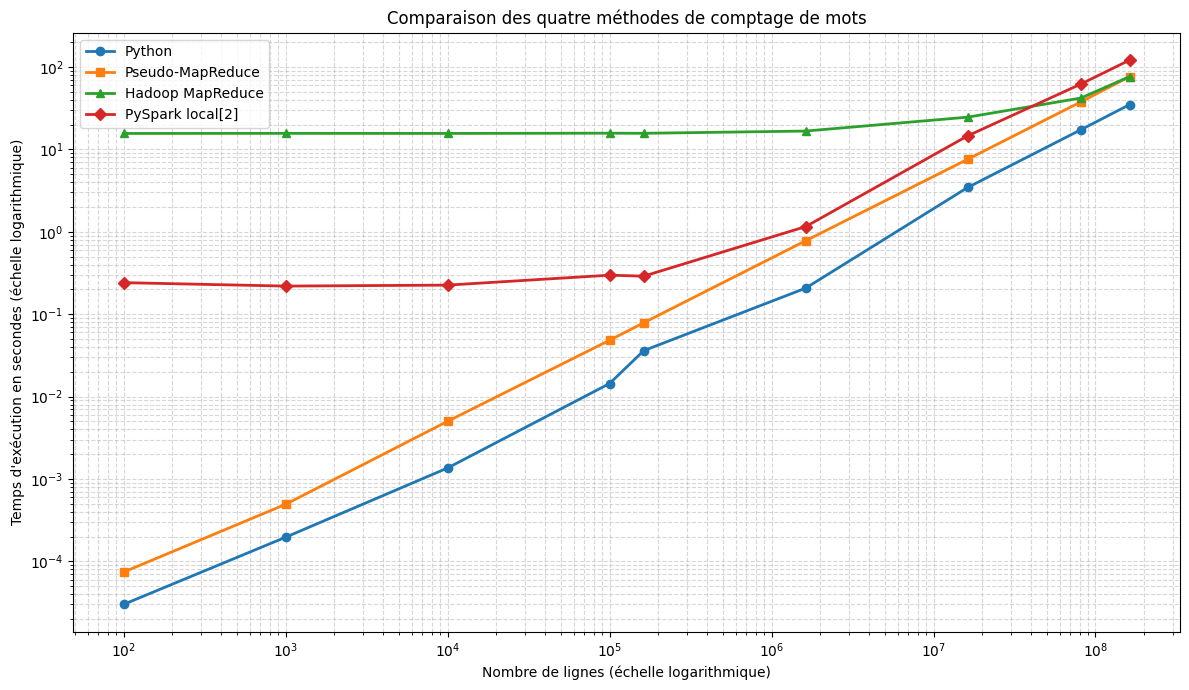

In [17]:
import matplotlib.pyplot as plt

# ============================================================
# GRAPHIQUE : COMPARAISON DES QUATRE MÉTHODES
# ============================================================

plt.figure(figsize=(12, 7))

courbes = [
    ("Python (s)", "o", "Python"),
    ("MapReduce (s)", "s", "Pseudo-MapReduce"),
    ("Hadoop job (s)", "^", "Hadoop MapReduce"),
    ("Spark (s)", "D", "PySpark local[2]"),
]

for colonne, marqueur, etiquette in courbes:
    mesures = df_benchmarks[colonne].notna()

    plt.plot(
        df_benchmarks.loc[mesures, "Nombre de lignes"],
        df_benchmarks.loc[mesures, colonne],
        marker=marqueur,
        linewidth=2,
        label=etiquette
    )

# Échelle logarithmique sur les deux axes : les temps mesurés s'étendent
# de la microseconde à la minute.
plt.xscale("log")
plt.yscale("log")

plt.xlabel("Nombre de lignes (échelle logarithmique)")
plt.ylabel("Temps d'exécution en secondes (échelle logarithmique)")

plt.title("Comparaison des quatre méthodes de comptage de mots")

plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [18]:
# Libération des ressources Spark
spark.stop()

print("Session Spark arrêtée.")

Session Spark arrêtée.
